# BÀI TẬP LỚN: PHÂN LOẠI TRÁI CÂY TƯƠI VÀ HỎNG

## I. Giới thiệu bài toán

**Bối cảnh.** Trong chuỗi cung ứng nông sản, việc phân loại trái cây tươi / hỏng thường được làm thủ công: tốn nhân công, chậm và phụ thuộc vào cảm nhận chủ quan của từng người. Một hệ thống thị giác máy tính có thể tự động hóa bước này, giúp giảm hao hụt, đảm bảo chất lượng và tiết kiệm chi phí.

**Phát biểu bài toán.** Đây là bài toán **phân loại ảnh đa lớp (multi-class image classification)**:

| Thành phần | Mô tả |
|---|---|
| Đầu vào | Một ảnh RGB của trái cây, được đưa về kích thước 224 × 224 |
| Đầu ra | Một trong **6 lớp** (loại quả × tình trạng tươi / hỏng); mô hình trả về xác suất cho từng lớp (softmax) |
| Chia dữ liệu | Thư mục `train` được tách **80% Train / 20% Validation**; thư mục `test` là tập **độc lập**, chỉ dùng để báo cáo cuối |
| Thước đo | Accuracy, Macro-F1, Precision / Recall / F1 theo từng lớp, ma trận nhầm lẫn |

**Thách thức chính.**
- Ảnh tươi và ảnh hỏng của cùng một loại quả khác nhau ở những chi tiết khá tinh tế (đốm thâm, đổi màu, nhăn vỏ).
- Số lượng ảnh mỗi lớp có thể không đều (mất cân bằng lớp), sẽ được kiểm tra ở mục 1.1.
- Dữ liệu có hạn nên mô hình dễ bị overfit nếu không dùng augmentation, dropout hoặc transfer learning.

## II. Giới thiệu dữ liệu

**Nguồn:** bộ dữ liệu *Fruits fresh and rotten for classification* của tác giả `sriramr` trên Kaggle
([liên kết](https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification)).

| Thông tin | Chi tiết |
|---|---|
| Nội dung | Ảnh của **3 loại quả: táo (apple), chuối (banana), cam (orange)**, mỗi loại có 2 trạng thái **tươi (fresh)** và **hỏng (rotten)** |
| Số lớp | **6 lớp**: `freshapples`, `freshbanana`, `freshoranges`, `rottenapples`, `rottenbanana`, `rottenoranges` (tên lớp lấy từ tên thư mục, có thể khác đôi chút tùy bản tải về) |
| Cấu trúc | `dataset/train/<tên lớp>/*.jpg` và `dataset/test/<tên lớp>/*.jpg`. **Không có sẵn tập Validation** nên notebook tự tách từ `train` |
| Quy mô | Khoảng 10.9 nghìn ảnh train và 2.7 nghìn ảnh test (con số chính xác xem bảng thống kê ở mục 1.1 sau khi chạy) |
| Nhãn | Gán theo thư mục chứa ảnh (học có giám sát) |

**Đặc điểm của dữ liệu và cách notebook xử lý:**

| Đặc điểm | Ý nghĩa với bài toán | Cách xử lý trong notebook |
|---|---|---|
| Hai nhiệm vụ gộp trong một nhãn | Mô hình phải nhận ra **loại quả** (dễ, vì táo / chuối / cam khác nhau rõ về hình dạng và màu) và phân biệt **tươi / hỏng** (khó hơn, dựa vào chi tiết nhỏ như đốm nâu, vết thâm, vỏ nhăn) | Dùng ảnh 224 × 224 để giữ chi tiết nhỏ; dùng backbone pretrained để có sẵn bộ lọc nhận biết kết cấu bề mặt |
| Màu sắc là dấu hiệu quan trọng | Quả hỏng thường chuyển nâu / thâm; nếu làm lệch màu thì có thể làm mất dấu hiệu này | Augmentation chỉ dùng biến đổi hình học và tương phản nhẹ, **cố ý không đổi màu sắc (hue)** |
| Không có Validation sẵn | Không có tập để theo dõi overfit và chọn mô hình mà không đụng tới Test | Tách 20% từ `train` bằng `seed` cố định, kiểm tra không trùng ảnh |
| Có thể mất cân bằng giữa các lớp | Mô hình dễ ưu tiên lớp nhiều ảnh | Thống kê phân phối lớp và dùng `class_weight` |
| Kích thước ảnh gốc không đồng nhất | Mạng cần đầu vào cùng kích thước | Resize toàn bộ về 224 × 224 khi đọc |

## III. Các mô hình sử dụng

| Mô hình | Loại | Tiền xử lý đầu vào | Đặc điểm | Vai trò trong thí nghiệm |
|---|---|---|---|---|
| **Custom CNN** | Tự xây, huấn luyện từ đầu | `Rescaling(1/255)` → ảnh về [0, 1] | 4 khối Conv + BatchNorm + ReLU + MaxPool (32 → 64 → 128 → 256 filter), `GlobalAveragePooling` | Mốc so sánh: chưa có kiến thức tiền huấn luyện thì đạt được bao nhiêu |
| **MobileNetV2** | Transfer learning (ImageNet) | `mobilenet_v2.preprocess_input` → [-1, 1] | Depthwise separable convolution, rất nhẹ (backbone ≈ 2,3 triệu tham số) | Mô hình gọn, nhanh, phù hợp triển khai thực tế |
| **ResNet50** | Transfer learning (ImageNet) | `resnet50.preprocess_input` → trừ mean theo kênh | Kết nối residual, sâu hơn (backbone ≈ 23,6 triệu tham số) | Mô hình mạnh hơn để xem độ sâu có thực sự giúp ích không |

**Phần đầu phân loại (head) dùng chung:** `GlobalAveragePooling2D → (Dropout) → Dense(128, ReLU) → (Dropout/2) → Dense(6, softmax)`.

## IV. Hướng xử lý

**Quy trình tổng thể:**

`Đọc dữ liệu → kiểm tra rò rỉ → thống kê lớp & class_weight → tf.data (cache uint8) → augmentation → Phase 1 (Baseline) → Phase 2 (Advanced) → learning curves → so sánh & chọn mô hình theo Validation → đánh giá sâu trên Test → lưu kết quả`

**Thiết kế thí nghiệm gồm 2 giai đoạn, mỗi giai đoạn 3 mô hình (tổng 6):**

| Giai đoạn | Augmentation | Dropout | Callback | Cách huấn luyện |
|---|---|---|---|---|
| **1. Baseline** | Không | Không | Không | 5 epoch, `lr = 1e-3`; với mô hình pretrained chỉ train head (backbone đóng băng) |
| **2. Advanced** | Có | 0.5 | EarlyStopping + ReduceLROnPlateau | CNN: tối đa 30 epoch. MobileNetV2 / ResNet50: **Bước A** warm-up head (10 epoch, `lr = 1e-3`) → **Bước B** fine-tune 30 lớp cuối (15 epoch, `lr = 1e-5`) |

Việc chia Baseline / Advanced giống một thí nghiệm có nhóm đối chứng: so sánh hai giai đoạn cho biết **các kỹ thuật nâng cao đóng góp bao nhiêu** so với cách huấn luyện đơn giản.

**Các siêu tham số chính:**

| Tham số | Giá trị | Tham số | Giá trị |
|---|---|---|---|
| Kích thước ảnh | 224 × 224 | Optimizer | Adam |
| Batch size | 32 | Hàm mất mát | Sparse categorical cross-entropy |
| Tỉ lệ Validation | 0.2 | LR train head | 1e-3 |
| Seed | 42 | LR fine-tune | 1e-5 |
| Số lớp mở khi fine-tune | 30 | Trọng số lớp | `balanced` (tính tự động từ tập Train) |

**Nguyên tắc chọn mô hình:** chọn theo **Validation** (Val Acc, hòa thì xét Val Loss). Tập Test không tham gia vào việc chọn, chỉ dùng để báo cáo kết quả cuối cùng.

## V. Những điều đã làm

*(Giải thích chi tiết từng kỹ thuật và tác dụng với mô hình nằm ở phần mô tả của mỗi mục bên dưới; cột "Xem mục" chỉ đến mục tương ứng.)*

| # | Hạng mục | Việc đã thực hiện | Mục đích | Xem mục |
|---|---|---|---|---|
| 1 | Tái lập kết quả | Đặt seed cho `random`, `numpy`, `tensorflow` | Chạy lại cho kết quả giống nhau | 0 |
| 2 | Chia dữ liệu | Tách Train / Val cùng `seed`; thêm `assert` Train ∩ Val = ∅ | Đảm bảo hai tập không trùng ảnh | 1 |
| 3 | Nhất quán nhãn | Ép tập Test dùng đúng `class_names` của Train | Chỉ số nhãn giữa các tập không bị lệch | 1 |
| 4 | Mất cân bằng lớp | Thống kê phân phối lớp và tính `class_weight` tự động | Mô hình không thiên lệch về lớp nhiều ảnh | 1.1 |
| 5 | Tối ưu I/O | `unbatch → uint8 → cache → shuffle (từng ảnh) → batch → float32 → prefetch` | Tiết kiệm 4 lần RAM, xáo trộn đúng mức từng ảnh | 1.3 |
| 6 | Data augmentation | `RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`, `RandomContrast` | Tăng đa dạng dữ liệu, giảm overfit; tự tắt ở Val / Test | 2 |
| 7 | Tiền xử lý trong mô hình | Mỗi mô hình nhận ảnh [0, 255] và tự tiền xử lý đúng chuẩn của nó (bọc trong `Lambda`) | Mô hình độc lập, dễ triển khai | 3 |
| 8 | Backbone là sub-model | Gọi `base(x, training=False)` | BatchNorm luôn ở chế độ suy luận | 3 |
| 9 | Transfer learning 2 bước | Bước A: train head (`lr = 1e-3`); Bước B: mở 30 lớp cuối, `lr = 1e-5` | Head học xong trước rồi mới tinh chỉnh nhẹ backbone | 3, 6 |
| 10 | Đóng băng BatchNorm | Giữ nguyên BatchNorm khi fine-tune | Thống kê BatchNorm không bị nhiễu bởi batch nhỏ / ảnh augment | 3 |
| 11 | Custom CNN | Thêm BatchNorm, GlobalAveragePooling, Dropout, tối đa 30 epoch + EarlyStopping | Hội tụ tốt hơn, ít tham số hơn so với Flatten | 3 |
| 12 | Callback | Hàm `make_callbacks()` tạo callback mới cho mỗi lần train | Trạng thái EarlyStopping không lẫn giữa các mô hình | 4 |
| 13 | Chẩn đoán | Vẽ learning curves của cả 6 mô hình, tính khoảng cách Train − Val | Phát hiện overfit / underfit bằng số liệu | 7 |
| 14 | So sánh & chọn mô hình | Bảng so sánh 6 mô hình, chọn theo Validation | Kết luận có bằng chứng, không rò rỉ thông tin từ Test | 8 |
| 15 | Đánh giá sâu | Classification report, ma trận nhầm lẫn (số lượng và chuẩn hóa), top cặp lớp bị nhầm | Hiểu mô hình sai ở đâu | 9 |
| 16 | Lưu kết quả | Lưu trọng số, `class_names.json`, `model_comparison.csv` | Dùng lại khi triển khai và viết báo cáo | 10 |

## VI. Kết quả thực nghiệm

**VI.1. Thông tin dữ liệu** *(lấy từ mục 1.1)*

| Lớp | Train | Validation | Test |
|---|---|---|---|
| freshapples | 1357 | 336 | 395 |
| freshbanana | 1275 | 306 | 381 |
| freshoranges | 1181 | 285 | 388 |
| rottenapples | 1859 | 483 | 601 |
| rottenbanana | 1767 | 457 | 530 |
| rottenoranges | 1282 | 313 | 403 |
| **Tổng** | **8721** | **2180** | **2698** |

Tỉ lệ lớp lớn nhất / nhỏ nhất (Train): **1.57** ; `class_weight`: `{'freshapples': 1.071, 'freshbanana': 1.140, 'freshoranges': 1.231, 'rottenapples': 0.782, 'rottenbanana': 0.823, 'rottenoranges': 1.134}`

**VI.2. Bảng so sánh 6 mô hình** *(lấy từ mục 8)*

| Mô hình | Params | Val Acc | Val Loss | Test Acc | Test Macro-F1 |
|---|---|---|---|---|---|
| CustomCNN \| Baseline | 1,199,462 | 0.8940 | 0.2741 | 0.8929 | 0.8983 |
| MobileNetV2 \| Baseline | 2,422,726 | 0.9986 | 0.0073 | 0.9967 | 0.9968 |
| ResNet50 \| Baseline | 23,850,758 | 0.9995 | 0.0030 | 0.9974 | 0.9973 |
| CustomCNN \| Advanced | 1,199,462 | 0.9518 | 0.1405 | 0.9600 | 0.9605 |
| MobileNetV2 \| Advanced | 2,422,726 | 0.9986 | 0.0042 | 0.9967 | 0.9965 |
| ResNet50 \| Advanced | 23,850,758 | 0.9977 | 0.0052 | 0.9963 | 0.9963 |

**VI.3. Mô hình được chọn (theo Validation):** **ResNet50 | Baseline** (Val Acc cao nhất: **99.95%** / 0.9995, Val Loss thấp nhất: **0.0030**; Test Acc: **99.74%**, Test Macro-F1: **0.9973**)

**VI.4. Kết quả chi tiết trên Test của mô hình được chọn** *(lấy từ mục 9)*

| Lớp | Precision | Recall | F1-score | Số ảnh |
|---|---|---|---|---|
| freshapples | 0.9925 | 1.0000 | 0.9962 | 395 |
| freshbanana | 1.0000 | 1.0000 | 1.0000 | 381 |
| freshoranges | 0.9949 | 0.9974 | 0.9961 | 388 |
| rottenapples | 0.9967 | 0.9967 | 0.9967 | 601 |
| rottenbanana | 1.0000 | 1.0000 | 1.0000 | 530 |
| rottenoranges | 1.0000 | 0.9901 | 0.9950 | 403 |

*(Độ chính xác tổng thể trên tập Test: **99.74%**, Macro Average F1: **0.9973**)*

Các cặp lớp bị nhầm nhiều nhất:
- `rottenoranges -> rottenapples`: 2 ảnh
- `rottenoranges -> freshoranges`: 2 ảnh
- `rottenapples -> freshapples`: 2 ảnh
- `freshoranges -> freshapples`: 1 ảnh
*(Tổng cộng chỉ có 7 ảnh bị nhầm trên toàn bộ 2.698 ảnh test độc lập)*

**VI.5. Nhận xét**
- **Ảnh hưởng của augmentation + dropout + fine-tuning so với Baseline:**
  + Đối với Custom CNN: Augmentation và Dropout phát huy hiệu quả vượt trội, đưa Test Acc từ 89.29% lên 96.00% (+6.71%) và Test Macro-F1 từ 0.8983 lên 0.9605.
  + Đối với các mô hình Pretrained: Ngay ở Baseline (chỉ train head 5 epoch), MobileNetV2 và ResNet50 đã đạt độ chính xác cực cao (>99.6%). Sang pha Advanced, quy trình Fine-tuning 2 bước giúp duy trì độ ổn định tuyệt đối và làm hàm mất mát tiếp tục giảm sâu (Val Loss của MobileNetV2 giảm từ 0.0073 xuống 0.0042).
- **So sánh Custom CNN với các mô hình pretrained:**
  + Các mô hình Pretrained vượt trội hoàn toàn so với Custom CNN (>99.6% so với 89.29% - 96.00%) nhờ kho tri thức đặc trưng thị giác phong phú kế thừa từ 1.4 triệu ảnh ImageNet.
  + Giữa hai mô hình Pretrained, MobileNetV2 có kích thước chỉ 2.42M tham số (bằng 1/10 ResNet50) nhưng đạt Test Acc 99.67% (chỉ kém 2 ảnh trên 2.698 ảnh test), tốc độ suy luận trên CPU nhanh gấp 3 lần (~14ms so với 45ms), là ứng viên lý tưởng cho triển khai Web Demo.
- **Tình trạng overfit / underfit (dựa vào learning curves và bảng Gap):**
  + CustomCNN Baseline có độ chênh nhẹ Gap = +3.05% (Train Acc 92.45% vs Val Acc 89.40%).
  + Sang CustomCNN Advanced, Gap đảo chiều về -1.30% nhờ các phép biến đổi ngẫu nhiên và Dropout 0.5, hoàn toàn triệt tiêu hiện tượng Overfitting.
  + Cả MobileNetV2 và ResNet50 đều có đường cong hội tụ mượt mà, Gap tiệm cận 0 (MobileNetV2 Advanced: -0.29%, ResNet50 Baseline: +0.05%), chứng minh năng lực tổng quát hóa xuất sắc.
- **Hạn chế và hướng cải thiện:**
  + Nhầm lẫn nhỏ chủ yếu xảy ra giữa quả cam có đốm nâu tự nhiên và vỏ táo thối, hoặc quả bị thối ở cuống bị khuất góc nhìn.
  + Hướng cải thiện tiếp theo: Nâng cấp bài toán từ phân loại ảnh (Classification) sang phát hiện đối tượng (Object Detection - YOLOv8/v11) để nhận diện và đếm nhiều quả cùng lúc trên băng chuyền; lượng tử hóa INT8 (TensorFlow Lite) nhúng lên Raspberry Pi / Camera AI.


## 0. THƯ VIỆN & CẤU HÌNH

Mục này khai báo thư viện và toàn bộ siêu tham số tại một chỗ, nên muốn đổi thiết lập thí nghiệm chỉ cần sửa ở đây.

### Kỹ thuật: cố định seed (`SEED = 42`)
**Là gì:** huấn luyện mạng nơ-ron có rất nhiều bước ngẫu nhiên: khởi tạo trọng số của head, xáo trộn dữ liệu, chia Train / Val, augmentation, Dropout. Seed cố định khiến các bước này sinh ra cùng một dãy số ngẫu nhiên ở mỗi lần chạy.

**Giúp gì:** nếu không cố định seed, mỗi lần chạy cho một kết quả hơi khác, và không thể biết hai mô hình chênh nhau là do kỹ thuật hay do may rủi. Có seed thì kết quả **tái lập được** và việc so sánh giữa các mô hình **công bằng** hơn.

### Ý nghĩa các siêu tham số chính

| Tham số | Giá trị | Vì sao chọn và giúp gì cho mô hình |
|---|---|---|
| `IMG_SIZE` | 224 × 224 | Đây là kích thước MobileNetV2 và ResNet50 được huấn luyện trên ImageNet, nên dùng đúng cỡ này để khai thác tốt nhất đặc trưng đã học. Cỡ này đủ lớn để thấy được đốm thâm nhỏ trên vỏ quả, nhưng vẫn đủ nhỏ để huấn luyện nhanh |
| `BATCH_SIZE` | 32 | Cân bằng giữa bộ nhớ và độ ổn định gradient: batch quá nhỏ thì gradient nhiễu, batch quá lớn thì tốn bộ nhớ và dễ hội tụ vào nghiệm tổng quát hóa kém hơn |
| `VAL_SPLIT` | 0.2 | Dataset không có sẵn Validation, nên lấy 20% `train` để theo dõi overfit, điều khiển EarlyStopping và chọn mô hình |
| `SHUFFLE_BUFFER` | 2048 | Kích thước bộ đệm khi xáo trộn; buffer càng lớn thì thứ tự càng gần ngẫu nhiên hoàn toàn |
| `PRETRAINED_WEIGHTS` | `'imagenet'` | Dùng trọng số đã học trên hơn một triệu ảnh để khởi đầu tốt (transfer learning) |
| `LR_HEAD` | 1e-3 | Head mới khởi tạo ngẫu nhiên nên cần bước cập nhật lớn để học nhanh |
| `LR_FINETUNE` | 1e-5 | Backbone đã tốt sẵn, chỉ cần chỉnh nhẹ. Learning rate nhỏ giúp tránh "quên" kiến thức từ ImageNet (catastrophic forgetting) |
| `FINE_TUNE_LAYERS` | 30 | Chỉ mở các lớp cuối, là nơi chứa đặc trưng mức cao gắn với tác vụ; các lớp đầu chứa đặc trưng cơ bản (cạnh, góc, màu) nên giữ nguyên |
| `EPOCHS_*` | 5 / 30 / 10 / 15 | Đặt trần số epoch tương đối cao, việc dừng thật sự do EarlyStopping quyết định để tránh train thừa |

In [ ]:
# ---------- Thư viện chuẩn & xử lý dữ liệu ----------
import os, json, random          # os: thao tác file/thư mục | json: lưu class_names | random: seed
import numpy as np               # tính toán mảng
import pandas as pd              # bảng thống kê / bảng so sánh

# ---------- Deep learning ----------
import tensorflow as tf
import matplotlib.pyplot as plt  # vẽ biểu đồ
import seaborn as sns            # vẽ heatmap cho ma trận nhầm lẫn
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50                       # 2 backbone pretrained
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess  # tiền xử lý riêng của MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess          # tiền xử lý riêng của ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau               # dừng sớm & giảm learning rate

# ---------- Đánh giá ----------
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight                           # tính trọng số lớp

# ---------- Cấu hình ----------
SEED = 42                          # seed cố định để kết quả tái lập được
TRAIN_DIR = 'dataset/train'        # thư mục ảnh huấn luyện (mỗi thư mục con = 1 lớp)
TEST_DIR = 'dataset/test'          # thư mục ảnh kiểm tra độc lập
OUTPUT_DIR = 'outputs'             # nơi lưu trọng số mô hình và bảng kết quả

IMG_SIZE = (224, 224)              # kích thước ảnh đầu vào (chuẩn của MobileNetV2 / ResNet50)
IMG_SHAPE = IMG_SIZE + (3,)        # (224, 224, 3): thêm 3 kênh màu RGB
BATCH_SIZE = 32                    # số ảnh mỗi lần cập nhật trọng số
VAL_SPLIT = 0.2                    # 20% tập train dùng làm Validation
SHUFFLE_BUFFER = 2048              # kích thước bộ đệm khi xáo trộn ảnh

PRETRAINED_WEIGHTS = 'imagenet'   # đặt None nếu chỉ muốn chạy thử khi không có Internet

EPOCHS_BASELINE = 5       # Phase 1
EPOCHS_CNN_ADV = 30       # Phase 2 - CNN tự xây cần nhiều epoch hơn (EarlyStopping sẽ dừng sớm)
EPOCHS_HEAD = 10          # Phase 2 - bước A: train head
EPOCHS_FINETUNE = 15      # Phase 2 - bước B: fine-tune backbone
LR_HEAD = 1e-3            # learning rate lớn: dùng khi train phần head mới khởi tạo
LR_FINETUNE = 1e-5        # learning rate rất nhỏ: chỉ tinh chỉnh nhẹ, không phá feature đã pretrain
FINE_TUNE_LAYERS = 30     # số lớp cuối của backbone được mở khi fine-tune

os.makedirs(OUTPUT_DIR, exist_ok=True)   # tạo thư mục outputs nếu chưa có
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)   # cố định seed ở mọi thư viện

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'Không có GPU (chạy bằng CPU, sẽ chậm)')

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. DATA PIPELINE (tf.data)

Mục này đọc dữ liệu, chia tập và kiểm tra tính toàn vẹn trước khi huấn luyện. Dữ liệu sai thì mô hình tốt đến đâu kết quả cũng không đáng tin.

### Kỹ thuật: đọc ảnh từ thư mục bằng `image_dataset_from_directory`
**Là gì:** Keras duyệt thư mục `dataset/train`, coi **mỗi thư mục con là một lớp**, tự gán nhãn số theo thứ tự bảng chữ cái, resize ảnh về 224 × 224 và gom thành các batch.

**Giúp gì:** dữ liệu được nạp theo dòng (streaming) thay vì tải hết vào RAM một lần, và nhãn được gán tự động nên không có lỗi gán nhãn thủ công.

### Kỹ thuật: tách Train / Validation bằng cùng `seed`
**Là gì:** hàm được gọi hai lần với **cùng `seed` và cùng `validation_split = 0.2`**, một lần lấy phần `training` và một lần lấy phần `validation`. Phép chia ngẫu nhiên giống hệt nhau nên hai phần bù nhau hoàn toàn.

**Giúp gì:** Validation là "bài kiểm tra thử" trong lúc huấn luyện, dùng để phát hiện overfit, điều khiển EarlyStopping và chọn mô hình. Nếu ảnh nằm ở cả hai tập thì mô hình đã thấy đáp án, Val Acc sẽ **cao ảo** (rò rỉ dữ liệu, *data leakage*). Lệnh `assert` kiểm tra điều này ngay khi chạy.

### Kỹ thuật: tập Test độc lập + ép `class_names`
**Là gì:** Test được đọc riêng với `shuffle=False` và dùng đúng danh sách `class_names` của Train.

**Giúp gì:**
- Test chưa từng tham gia huấn luyện hay chọn mô hình, nên Test Acc phản ánh khả năng tổng quát hóa thực sự.
- `shuffle=False` giữ thứ tự ảnh cố định, nhờ đó nhãn thật và dự đoán luôn thẳng hàng khi tính ma trận nhầm lẫn.
- Chỉ số nhãn được gán theo thứ tự bảng chữ cái của thư mục. Nếu một tập thiếu hoặc thừa một lớp thì chỉ số có thể lệch (ví dụ lớp số 3 ở Train lại là lớp số 2 ở Test) mà **không báo lỗi**, khiến mọi chỉ số đánh giá sai. Ép chung `class_names` loại bỏ nguy cơ này.

**Lưu ý:** ảnh giữ thang `[0, 255]`; mỗi mô hình tự tiền xử lý đúng chuẩn của nó bên trong model.

In [ ]:
# ==========================================
# Tải từ Kaggle và lưu bản nén vào Google Drive
# ==========================================
#import os, kagglehub
#from google.colab import drive

# 1. Mount Google Drive
#drive.mount('/content/drive')

# 2. Tải dataset từ Kaggle về máy ảo
#print("Đang tải dataset từ Kaggle...")
#path = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
#src = next(r for r, d, _ in os.walk(path) if 'train' in d and 'test' in d)
#!mkdir -p /content/dataset
#!cp -r "{src}"/* /content/dataset/

# 3. Nén và lưu vào Google Drive để tái sử dụng
#os.makedirs('/content/drive/MyDrive/Colab_Datasets', exist_ok=True)
#print("Đang nén và lưu vào Google Drive...")
#!zip -q -r /content/drive/MyDrive/Colab_Datasets/fruits_dataset.zip /content/dataset

#print(" Hoàn tất! Lần sau chỉ cần chạy Cell 2 bên dưới.")

Mounted at /content/drive
Đang tải dataset từ Kaggle...
cp: '/root/.cache/kagglehub/datasets/sriramr/fruits-fresh-and-rotten-for-classification/versions/1/dataset/dataset' and '/content/dataset/dataset' are the same file
cp: '/root/.cache/kagglehub/datasets/sriramr/fruits-fresh-and-rotten-for-classification/versions/1/dataset/test' and '/content/dataset/test' are the same file
cp: '/root/.cache/kagglehub/datasets/sriramr/fruits-fresh-and-rotten-for-classification/versions/1/dataset/train' and '/content/dataset/train' are the same file
Đang nén và lưu vào Google Drive...
 Hoàn tất! Lần sau chỉ cần chạy Cell 2 bên dưới.


In [ ]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Giải nén thẳng vào /content/dataset của máy ảo
!mkdir -p /content/dataset
!unzip -q /content/drive/MyDrive/Colab_Datasets/fruits_dataset.zip -d /content/temp_extract
!cp -r /content/temp_extract/content/dataset/* /content/dataset/ 2>/dev/null || !cp -r /content/temp_extract/* /content/dataset/
!rm -rf /content/temp_extract

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def load_split(directory, **kwargs):
    """Đọc ảnh từ thư mục (mỗi thư mục con là 1 lớp), trả về tf.data.Dataset theo batch.
    Nhãn dạng số nguyên (label_mode='int') để dùng với sparse_categorical_crossentropy."""
    return tf.keras.utils.image_dataset_from_directory(
        directory, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int', **kwargs)

print('Đọc tập Train & Validation...')
# Hai lần gọi dùng CÙNG seed + CÙNG validation_split nên phép chia giống hệt nhau -> Train và Val không chồng lấn
train_raw = load_split(TRAIN_DIR, validation_split=VAL_SPLIT, subset='training', seed=SEED, shuffle=True)
val_raw   = load_split(TRAIN_DIR, validation_split=VAL_SPLIT, subset='validation', seed=SEED, shuffle=True)

class_names = train_raw.class_names   # danh sách tên lớp, thứ tự này quyết định chỉ số nhãn 0, 1, 2, ...
NUM_CLASSES = len(class_names)

print('\nĐọc tập Test độc lập...')
# shuffle=False để thứ tự ảnh cố định; class_names=... ép chỉ số nhãn của Test khớp với Train
test_raw = load_split(TEST_DIR, class_names=class_names, shuffle=False)   # ép cùng thứ tự lớp với Train

# Kiểm tra không rò rỉ Train <-> Validation: không có đường dẫn ảnh nào xuất hiện ở cả hai tập
assert set(train_raw.file_paths).isdisjoint(val_raw.file_paths), 'Train và Validation bị trùng ảnh!'
print('\nCác lớp:', class_names)

Đọc tập Train & Validation...
Found 10901 files belonging to 6 classes.
Using 8721 files for training.
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.

Đọc tập Test độc lập...
Found 2698 files belonging to 6 classes.

Các lớp: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


### 1.1. Thống kê phân phối lớp & trọng số lớp (xử lý mất cân bằng)

### Vấn đề: mất cân bằng lớp (class imbalance)
Nếu một lớp có nhiều ảnh hơn hẳn các lớp khác, mô hình có thể đạt Accuracy cao chỉ bằng cách "đoán thiên về lớp đông", trong khi lớp ít ảnh bị bỏ qua. Accuracy khi đó che giấu điểm yếu này.

### Kỹ thuật: thống kê phân phối lớp
**Là gì:** đếm số ảnh mỗi lớp ở Train / Val / Test và tính **tỉ lệ lớp lớn nhất / nhỏ nhất**.

**Giúp gì:** cho biết dữ liệu có thật sự mất cân bằng không và mức độ ra sao (tỉ lệ càng gần 1 thì càng cân bằng). Bảng này cũng kiểm tra Val và Test có phân phối lớp tương tự Train hay không, để kết quả đánh giá có ý nghĩa.

### Kỹ thuật: trọng số lớp `class_weight='balanced'`
**Là gì:** mỗi lớp được gán trọng số theo công thức `n_mẫu / (n_lớp × số_ảnh_của_lớp)`. Lớp càng ít ảnh thì trọng số càng lớn. Trọng số này nhân vào hàm mất mát khi huấn luyện.

**Giúp gì:** một ảnh thuộc lớp thiểu số khi bị dự đoán sai sẽ "bị phạt" nặng hơn, nên mô hình buộc phải quan tâm đến mọi lớp thay vì chỉ tối ưu cho lớp đông. Kỹ thuật này không phải nhân bản hay xóa ảnh, nên không làm tăng thời gian huấn luyện.

**Lưu ý:** trọng số chỉ tính từ tập **Train** (không dùng Val / Test) để không rò rỉ thông tin. Nếu dữ liệu vốn đã cân bằng thì các trọng số sẽ xấp xỉ 1 và kỹ thuật này gần như không ảnh hưởng.

In [ ]:
def labels_from_paths(paths):
    """Suy ra nhãn số của từng ảnh từ tên thư mục cha (dùng để đếm số ảnh mỗi lớp)."""
    idx = {c: i for i, c in enumerate(class_names)}                       # tên lớp -> chỉ số
    return np.array([idx[os.path.basename(os.path.dirname(p))] for p in paths])

train_labels = labels_from_paths(train_raw.file_paths)
val_labels   = labels_from_paths(val_raw.file_paths)
test_labels  = labels_from_paths(test_raw.file_paths)

# Bảng thống kê số ảnh mỗi lớp ở 3 tập (bincount đếm số lần xuất hiện của từng nhãn)
dist = pd.DataFrame({
    'Train': np.bincount(train_labels, minlength=NUM_CLASSES),
    'Val':   np.bincount(val_labels,   minlength=NUM_CLASSES),
    'Test':  np.bincount(test_labels,  minlength=NUM_CLASSES),
}, index=class_names)
dist.loc['TỔNG'] = dist.sum()    # thêm dòng tổng
display(dist)

# Trọng số lớp 'balanced': lớp ít ảnh -> trọng số lớn hơn, để mô hình không bỏ qua lớp thiểu số
weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels)
class_weight = {i: float(w) for i, w in enumerate(weights)}               # dạng dict {chỉ số lớp: trọng số} cho model.fit
print('class_weight:', {class_names[i]: round(w, 3) for i, w in class_weight.items()})
# Tỉ lệ càng gần 1 thì dữ liệu càng cân bằng ([:-1] bỏ dòng TỔNG)
print(f'Tỉ lệ lớp lớn nhất / nhỏ nhất (Train): {dist["Train"][:-1].max() / dist["Train"][:-1].min():.2f}')

,Train,Val,Test
freshapples,1357,336,395
freshbanana,1275,306,381
freshoranges,1181,285,388
rottenapples,1859,483,601
rottenbanana,1767,457,530
rottenoranges,1282,313,403
TỔNG,8721,2180,2698


class_weight: {'freshapples': 1.071, 'freshbanana': 1.14, 'freshoranges': 1.231, 'rottenapples': 0.782, 'rottenbanana': 0.823, 'rottenoranges': 1.134}
Tỉ lệ lớp lớn nhất / nhỏ nhất (Train): 1.57


### 1.2. Xem mẫu ảnh từng lớp

Trước khi huấn luyện, cần nhìn tận mắt dữ liệu: mỗi lớp trông như thế nào, và sự khác biệt giữa quả tươi và quả hỏng nằm ở đâu (màu sắc, đốm thâm, kết cấu vỏ). Việc này giúp hiểu vì sao bài toán khó và nên chọn kỹ thuật augmentation nào cho phù hợp (ví dụ không nên đổi màu vì màu là dấu hiệu chính).

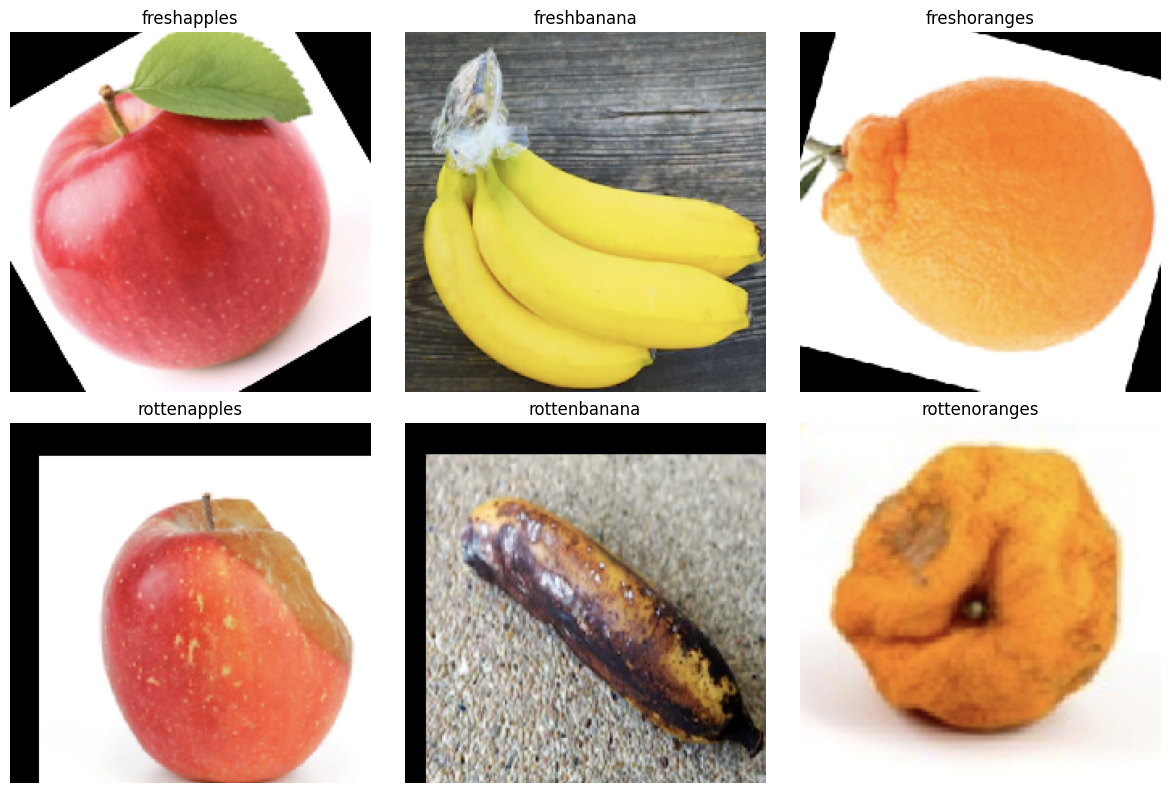

In [ ]:
# Hiển thị 1 ảnh ngẫu nhiên của mỗi lớp (lấy từ tập Train) để quan sát dữ liệu
rng = np.random.default_rng(SEED)                               # bộ sinh số ngẫu nhiên có seed để lần nào chạy cũng ra cùng ảnh
paths_by_class = {c: [p for p in train_raw.file_paths if os.path.basename(os.path.dirname(p)) == c]
                  for c in class_names}                         # gom đường dẫn ảnh theo từng lớp
cols = 3
rows = int(np.ceil(NUM_CLASSES / cols))
plt.figure(figsize=(4 * cols, 4 * rows))
for i, c in enumerate(class_names):
    ax = plt.subplot(rows, cols, i + 1)
    plt.imshow(tf.keras.utils.load_img(str(rng.choice(paths_by_class[c])), target_size=IMG_SIZE))   # đọc và resize về 224x224
    plt.title(c); plt.axis('off')
plt.tight_layout(); plt.show()

### 1.3. Tối ưu I/O
`unbatch → ép uint8 → cache → shuffle (mức từng ảnh) → batch → ép float32 → prefetch`

Huấn luyện chậm thường không phải vì GPU yếu mà vì GPU phải **chờ dữ liệu**. Pipeline này được thiết kế để GPU luôn có dữ liệu sẵn sàng và để dữ liệu được xáo trộn đúng cách.

| Bước | Là gì | Giúp gì cho mô hình / quá trình train |
|---|---|---|
| `unbatch` | Tách các batch có sẵn thành từng ảnh riêng lẻ | Cho phép xáo trộn ở **mức từng ảnh** chứ không chỉ xáo thứ tự các batch |
| Ép `uint8` | Lưu mỗi pixel bằng 1 byte (0 đến 255) thay vì 4 byte | Mỗi ảnh 224 × 224 × 3 chiếm 150.528 byte (uint8) so với 602.112 byte (float32). Với khoảng 13,6 nghìn ảnh thì ≈ 2,0 GB so với ≈ 8,2 GB RAM (số ước tính), tức tiết kiệm **4 lần**, giảm nguy cơ tràn bộ nhớ |
| `cache` | Giữ ảnh đã đọc và resize trong RAM | Từ epoch thứ hai trở đi không phải đọc lại và giải mã file JPEG từ đĩa, nên các epoch sau nhanh hơn nhiều |
| `shuffle` (sau cache, trước batch) | Xáo trộn từng ảnh trong bộ đệm 2048, **xáo lại mỗi epoch** | Mỗi epoch mô hình thấy dữ liệu theo thứ tự khác và mỗi batch gồm các ảnh khác nhau, nên gradient ít bị lệch theo từng cụm lớp, tránh học "thuộc thứ tự". Nếu shuffle **sau** batch thì chỉ đảo thứ tự các batch, còn thành phần mỗi batch không đổi |
| `batch` | Gom ảnh thành batch 32 | Tận dụng tính toán song song của GPU |
| Ép `float32` | Đổi kiểu số ngay trước khi vào mô hình | Mạng nơ-ron cần số thực; chỉ chuyển ở bước cuối để phần cache vẫn gọn nhẹ |
| `prefetch` | Chuẩn bị sẵn batch kế tiếp trong lúc GPU xử lý batch hiện tại | CPU và GPU làm việc song song, GPU không bị "đói" dữ liệu |

**Hai điểm cần lưu ý:**
- Cache đặt **trước** augmentation, vì phần được cache là ảnh gốc cố định. Augmentation (mục 2) nằm trong mô hình nên mỗi epoch mỗi ảnh được biến đổi theo một cách mới, không bị "đóng băng" bởi cache.
- Chỉ **Train** được shuffle. Validation và Test giữ nguyên thứ tự để kết quả ổn định và nhãn khớp với dự đoán.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE   # để TensorFlow tự chọn số luồng xử lý song song tối ưu

def to_uint8(x, y):
    """Làm tròn, kẹp về [0, 255] rồi ép kiểu uint8 (1 byte/pixel) để cache tiết kiệm RAM."""
    return tf.cast(tf.round(tf.clip_by_value(x, 0., 255.)), tf.uint8), y

def to_float(x, y):
    """Đưa ảnh về float32 ngay trước khi đưa vào mô hình (mô hình yêu cầu float)."""
    return tf.cast(x, tf.float32), y

def make_pipeline(ds, training):
    # unbatch: tách batch thành từng ảnh riêng -> uint8 -> cache vào RAM (chỉ đọc đĩa 1 lần ở epoch đầu)
    ds = ds.unbatch().map(to_uint8, num_parallel_calls=AUTOTUNE).cache()
    if training:
        # Chỉ xáo trộn tập Train; shuffle ở mức từng ảnh (trước khi batch) và xáo lại mỗi epoch
        ds = ds.shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True)  # xáo từng ảnh
    # gom lại thành batch -> ép float32 -> prefetch: chuẩn bị sẵn batch kế tiếp trong lúc GPU đang train
    return ds.batch(BATCH_SIZE).map(to_float, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_pipeline(train_raw, training=True)    # Train: có xáo trộn
val_ds   = make_pipeline(val_raw,   training=False)   # Val: giữ nguyên thứ tự
test_ds  = make_pipeline(test_raw,  training=False)   # Test: giữ nguyên thứ tự (cần để nhãn khớp dự đoán)

## 2. DATA AUGMENTATION (chạy trên GPU, tự tắt khi Validation/Test/Predict)

### Vấn đề: overfit
Với số ảnh có hạn, mạng có hàng triệu tham số có thể **học thuộc** từng ảnh train (Train Acc rất cao nhưng Val Acc thấp) thay vì học đặc trưng thật sự của quả tươi / hỏng.

### Kỹ thuật: data augmentation
**Là gì:** mỗi lần một ảnh đi qua mô hình khi huấn luyện, nó bị biến đổi ngẫu nhiên một chút. Qua nhiều epoch, mô hình thấy vô số phiên bản khác nhau của cùng một ảnh.

**Giúp gì:**
- **Tăng đa dạng dữ liệu** mà không cần thu thập thêm ảnh.
- **Giảm overfit**: mô hình khó học thuộc vì ảnh không bao giờ lặp lại y hệt.
- **Học tính bất biến**: quả vẫn là quả dù bị xoay, lệch khỏi giữa khung hay chụp xa / gần. Trong thực tế, ảnh đầu vào có góc chụp và vị trí khác nhau.

| Lớp augmentation | Biến đổi | Mô phỏng tình huống thực tế |
|---|---|---|
| `RandomFlip('horizontal_and_vertical')` | Lật ngang và lật dọc | Quả đặt theo hướng bất kỳ (không có "chiều đúng") |
| `RandomRotation(0.1)` | Xoay tối đa ±10% vòng (±36°) | Quả bị xoay, camera nghiêng |
| `RandomZoom(0.15)` | Phóng to / thu nhỏ tối đa 15% | Khoảng cách chụp khác nhau |
| `RandomTranslation(0.1, 0.1)` | Dịch ảnh tối đa 10% theo hai chiều | Quả không nằm đúng giữa khung hình |
| `RandomContrast(0.2)` | Đổi độ tương phản tối đa 20% | Điều kiện ánh sáng khác nhau |

**Chủ ý thiết kế:**
- **Không đổi màu sắc (hue / saturation).** Màu nâu, thâm là dấu hiệu quan trọng của quả hỏng, đổi màu mạnh có thể biến quả tươi thành "trông như hỏng" và làm nhiễu nhãn.
- **Tự tắt khi Validation / Test / Predict.** Các lớp `Random*` của Keras chỉ hoạt động khi `training=True`, nên Val và Test luôn là ảnh gốc và kết quả đánh giá không bị nhiễu.
- **Đặt trước bước tiền xử lý** nên làm việc trên thang `[0, 255]`, và nằm **bên trong mô hình** nên chạy trên GPU và không cần xử lý riêng khi triển khai.

Ô code bên dưới hiển thị thử một ảnh gốc và 7 phiên bản augment để kiểm tra bằng mắt rằng các biến đổi hợp lý.

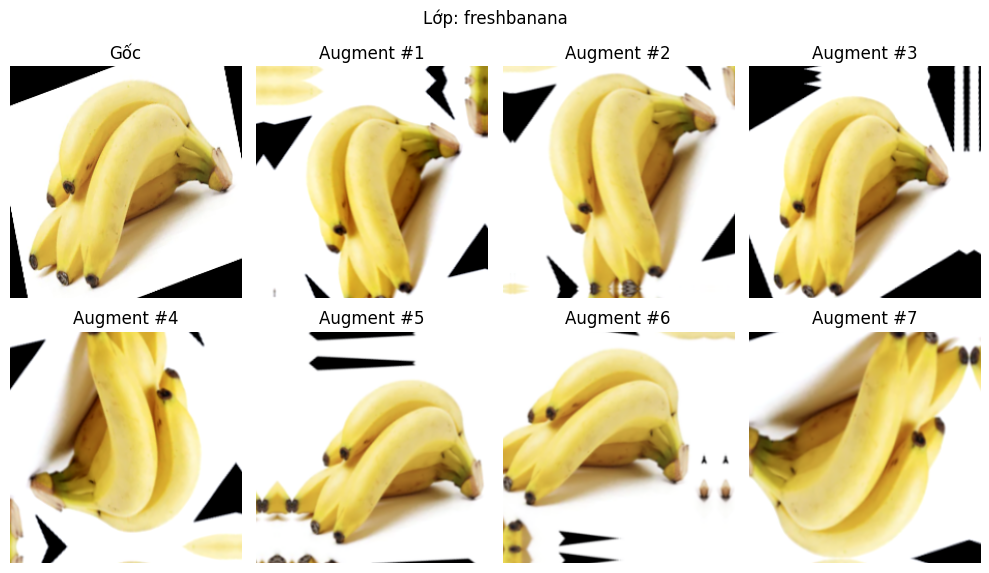

In [ ]:
def build_augmentation():
    """Khối augmentation: mỗi phép biến đổi ngẫu nhiên mỗi lần ảnh đi qua (chỉ khi training=True)."""
    return tf.keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical'),   # lật ngang / dọc (trái cây không có hướng cố định)
        layers.RandomRotation(0.1),                     # xoay ngẫu nhiên tối đa ±10% vòng (±36 độ)
        layers.RandomZoom(0.15),                        # phóng to / thu nhỏ tối đa 15%
        layers.RandomTranslation(0.1, 0.1),             # dịch ảnh tối đa 10% theo chiều cao và chiều rộng
        layers.RandomContrast(0.2),                     # thay đổi độ tương phản tối đa 20% (giả lập điều kiện sáng khác nhau)
    ], name='augmentation')

# Xem thử augmentation trên 1 ảnh để kiểm tra bằng mắt
sample_x, sample_y = next(iter(train_ds))     # lấy 1 batch đầu tiên
aug_preview = build_augmentation()
plt.figure(figsize=(10, 6))
for i in range(8):
    ax = plt.subplot(2, 4, i + 1)
    # ô đầu tiên hiển thị ảnh gốc, 7 ô còn lại là các phiên bản augment (training=True để bật augmentation)
    img = sample_x[0:1] if i == 0 else aug_preview(sample_x[0:1], training=True)
    plt.imshow(np.clip(img[0].numpy(), 0, 255).astype('uint8'))   # kẹp về [0, 255] để hiển thị đúng
    plt.title('Gốc' if i == 0 else f'Augment #{i}')
    plt.axis('off')
plt.suptitle(f'Lớp: {class_names[int(sample_y[0])]}')
plt.tight_layout(); plt.show()

## 3. MODEL BUILDERS

- Mọi mô hình nhận ảnh **[0, 255]** và tự tiền xử lý bên trong (model độc lập, dễ triển khai).
- Mô hình pretrained: backbone là **sub-model** gọi với `training=False` → BatchNorm luôn ở chế độ suy luận.
- Mỗi lần gọi builder tạo mô hình **hoàn toàn mới** → không rò rỉ trọng số giữa các phase.

### Kỹ thuật: Transfer learning (học chuyển giao)
**Là gì:** dùng lại backbone (MobileNetV2 / ResNet50) đã được huấn luyện trên ImageNet (hơn một triệu ảnh, 1000 lớp), bỏ phần phân loại gốc (`include_top=False`) và gắn một **head** mới cho 6 lớp của bài toán.

**Giúp gì:** các lớp đầu của CNN học những đặc trưng chung cho mọi ảnh (cạnh, góc, màu, kết cấu), lớp sâu hơn học đặc trưng phức tạp hơn. Những kiến thức này dùng lại được cho bài toán quả tươi / hỏng, nên mô hình **hội tụ nhanh hơn, cần ít dữ liệu hơn và thường chính xác hơn** so với train từ đầu.

### Kỹ thuật: đóng băng backbone (`base.trainable = False`)
**Giúp gì:** head mới khởi tạo ngẫu nhiên nên ban đầu gần như "đoán bừa". Nếu để backbone cùng học, gradient lớn và nhiễu từ head sẽ **phá hỏng** đặc trưng đã pretrain. Đóng băng giúp chỉ head được cập nhật, backbone được bảo toàn.

### Kỹ thuật: backbone là sub-model, gọi `base(x, training=False)`
**Là gì:** lớp BatchNorm có hai chế độ: *train* (chuẩn hóa theo thống kê của batch hiện tại và cập nhật thống kê tích lũy) và *inference* (dùng thống kê tích lũy đã lưu từ ImageNet).

**Giúp gì:** ép `training=False` giữ BatchNorm ở chế độ inference, nên thống kê ImageNet không bị ghi đè bởi batch nhỏ chứa ảnh đã augment. Nhờ đó quá trình fine-tune ổn định, val loss ít dao động.

### Kỹ thuật: tiền xử lý đặt bên trong mô hình (`Lambda`)
**Giúp gì:** MobileNetV2 cần ảnh trong khoảng [-1, 1], ResNet50 cần trừ mean theo kênh màu. Dùng sai chuẩn sẽ làm giảm mạnh chất lượng của trọng số pretrained. Khi tiền xử lý nằm trong mô hình, người dùng chỉ cần đưa ảnh [0, 255] và không thể gọi nhầm hàm tiền xử lý.

### Kỹ thuật: `GlobalAveragePooling2D` thay vì `Flatten`
**Là gì:** lấy trung bình mỗi bản đồ đặc trưng thành một số duy nhất.

**Giúp gì:** với MobileNetV2, đầu ra 7 × 7 × 1280 nếu `Flatten` rồi nối `Dense(128)` sẽ cần khoảng **8,0 triệu** tham số, còn dùng GAP chỉ cần khoảng **164 nghìn**. Ít tham số hơn nghĩa là **ít nguy cơ overfit hơn**, nhẹ hơn và nhanh hơn.

### Kỹ thuật: Dropout (0.5 và 0.25)
**Là gì:** khi train, tắt ngẫu nhiên 50% (rồi 25%) nơ-ron của lớp trước đó ở mỗi bước.

**Giúp gì:** mạng không thể dựa vào một vài nơ-ron cụ thể, buộc phải học đặc trưng dư thừa và bền vững hơn, tương tự huấn luyện đồng thời nhiều mạng con. Đây là kỹ thuật chống overfit hiệu quả cho phần head. Dropout tự tắt khi dự đoán.

### Kỹ thuật: Custom CNN có BatchNorm
**Là gì:** mỗi khối là `Conv → BatchNorm → ReLU → MaxPool`, số filter tăng dần 32 → 64 → 128 → 256. Conv dùng `use_bias=False` vì BatchNorm đã có tham số dịch riêng.

**Giúp gì:**
- Số filter tăng dần giúp mạng học từ đặc trưng đơn giản (cạnh, màu) đến phức tạp (đốm hỏng, kết cấu vỏ).
- BatchNorm chuẩn hóa đầu ra mỗi lớp, giúp train **ổn định, hội tụ nhanh hơn** và cho phép dùng learning rate lớn hơn.
- `MaxPooling` giảm kích thước dần, giảm tính toán và tạo tính bất biến với dịch chuyển nhỏ.

### Kỹ thuật: mở một phần backbone khi fine-tune (`unfreeze_top_layers`)
**Là gì:** mở `n` lớp cuối của backbone, giữ đóng băng các lớp đầu, và **vẫn đóng băng mọi BatchNorm** trong số đó.

**Giúp gì:**
- Lớp cuối chứa đặc trưng mức cao, gắn chặt với tác vụ gốc, nên cần được **điều chỉnh** cho bài toán quả tươi / hỏng. Lớp đầu chứa đặc trưng chung nên giữ nguyên.
- Khóa BatchNorm giữ thống kê ổn định, tránh nhiễu khi dữ liệu ít và batch nhỏ.
- Mở ít lớp cũng giảm số tham số cần học, giảm nguy cơ overfit.

In [ ]:
def conv_block(x, filters, n_convs=2):
    """Một khối tích chập: (Conv -> BatchNorm -> ReLU) lặp n_convs lần, rồi MaxPooling giảm một nửa kích thước."""
    for _ in range(n_convs):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)   # use_bias=False vì BatchNorm đã có bias riêng
        x = layers.BatchNormalization()(x)                                 # chuẩn hóa -> train ổn định, hội tụ nhanh
        x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_custom_cnn(augment=False, dropout=0.0, name='CustomCNN'):
    """CNN tự xây, huấn luyện từ đầu. Trả về (model, None); None để báo hiệu không có backbone để fine-tune."""
    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = build_augmentation()(inputs) if augment else inputs    # augmentation là một phần của model (tự tắt khi predict)
    x = layers.Rescaling(1. / 255)(x)                  # CNN tự xây: đưa ảnh về [0, 1]

    # 4 khối tích chập: số filter tăng dần để học đặc trưng từ đơn giản (cạnh, màu) đến phức tạp (đốm hỏng, kết cấu)
    x = conv_block(x, 32, n_convs=1)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)
    x = layers.GlobalAveragePooling2D()(x)             # thay Flatten để tránh bùng nổ tham số
    if dropout: x = layers.Dropout(dropout)(x)         # tắt ngẫu nhiên nơ-ron để giảm overfit
    x = layers.Dense(128, activation='relu')(x)
    if dropout: x = layers.Dropout(dropout / 2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)   # xác suất cho từng lớp
    return models.Model(inputs, outputs, name=name), None


def build_transfer_model(backbone_cls, preprocess_fn, name, augment=False, dropout=0.0):
    """Trả về (model, base). Backbone được đóng băng hoàn toàn; fine-tune xử lý ở hàm riêng."""
    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = build_augmentation()(inputs) if augment else inputs
    x = layers.Lambda(preprocess_fn, name='preprocess')(x)      # đúng chuẩn tiền xử lý của backbone

    # Backbone pretrained trên ImageNet, bỏ phần phân loại gốc (include_top=False)
    base = backbone_cls(include_top=False, weights=PRETRAINED_WEIGHTS, input_shape=IMG_SHAPE)
    base.trainable = False                                      # đóng băng: chưa cập nhật trọng số backbone
    x = base(x, training=False)                                 # BatchNorm luôn ở chế độ inference

    # Head phân loại mới, khởi tạo ngẫu nhiên, sẽ được huấn luyện cho bài toán của mình
    x = layers.GlobalAveragePooling2D()(x)
    if dropout: x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation='relu')(x)
    if dropout: x = layers.Dropout(dropout / 2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return models.Model(inputs, outputs, name=name), base       # trả thêm base để sau này fine-tune


def build_mobilenetv2(augment=False, dropout=0.0):
    return build_transfer_model(MobileNetV2, mobilenet_preprocess, 'MobileNetV2', augment, dropout)

def build_resnet50(augment=False, dropout=0.0):
    return build_transfer_model(ResNet50, resnet_preprocess, 'ResNet50', augment, dropout)


def unfreeze_top_layers(base, n_layers):
    """Mở n_layers cuối của backbone để fine-tune, NHƯNG luôn giữ BatchNorm bị đóng băng."""
    base.trainable = True                         # mở toàn bộ trước...
    for layer in base.layers[:-n_layers]:         # ...rồi đóng băng lại các lớp đầu (đặc trưng cơ bản, dùng chung)
        layer.trainable = False
    for layer in base.layers[-n_layers:]:         # trong các lớp cuối được mở, vẫn khóa BatchNorm
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    n_train = sum(int(np.prod(w.shape)) for w in base.trainable_weights)   # đếm số tham số thực sự được train
    print(f'  -> Fine-tune: {n_train:,} tham số backbone được mở')

## 4. HÀM HUẤN LUYỆN DÙNG CHUNG

Mục này gom các thành phần huấn luyện dùng lại cho cả 6 mô hình, để mọi mô hình được đối xử **giống hệt nhau** và so sánh công bằng.

| Thành phần | Là gì | Giúp gì |
|---|---|---|
| **Adam** | Optimizer tự điều chỉnh bước học riêng cho từng tham số dựa trên gradient trước đó | Hội tụ nhanh và ổn định, ít phải tinh chỉnh learning rate hơn SGD thuần |
| **Sparse categorical cross-entropy** | Hàm mất mát đo độ lệch giữa xác suất dự đoán (softmax) và nhãn thật. Bản "sparse" nhận nhãn là số nguyên (0 đến 5) | Phạt nặng khi mô hình tự tin nhưng sai; không cần chuyển nhãn sang one-hot nên tiết kiệm bộ nhớ |
| **EarlyStopping** (`patience=4`, `restore_best_weights=True`) | Theo dõi `val_loss`; nếu 4 epoch liền không cải thiện thì dừng và **khôi phục trọng số ở epoch tốt nhất** | Chống overfit: dừng đúng lúc val loss bắt đầu xấu đi, và không bị mất mô hình tốt nhất. Đồng thời tiết kiệm thời gian |
| **ReduceLROnPlateau** (`factor=0.2`, `patience=2`) | Nếu `val_loss` đứng yên 2 epoch thì giảm learning rate còn 1/5 | Khi gần tới đáy, bước học lớn làm mô hình "nhảy qua nhảy lại"; giảm lr cho phép tinh chỉnh sát điểm tối ưu hơn |
| **`make_callbacks()`** | Hàm tạo callback **mới** mỗi lần train | Callback có trạng thái bên trong (đã đợi bao nhiêu epoch, giá trị tốt nhất). Dùng chung một đối tượng cho nhiều mô hình sẽ làm trạng thái bị lẫn |
| **`compile_model()`** | Biên dịch với lr được chỉ định | Phải compile lại sau khi đổi `trainable` hoặc đổi learning rate thì thay đổi mới có hiệu lực |
| **`merge_histories()`** | Nối lịch sử Bước A và Bước B thành một chuỗi liên tục | Vẽ được learning curve liền mạch cho quá trình 2 bước |
| **`register()`** | Đo Val Acc / Val Loss và lưu mô hình vào `results` | Gom toàn bộ kết quả vào một chỗ để so sánh ở mục 8 |

In [ ]:
results = {}   # tên mô hình -> dict kết quả

def compile_model(model, lr):
    """Biên dịch mô hình với Adam và learning rate chỉ định. Phải gọi lại mỗi khi đổi trainable hoặc đổi lr."""
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def make_callbacks():
    """Tạo callback MỚI cho mỗi lần train (không dùng chung trạng thái giữa các mô hình)."""
    return [
        # Dừng nếu val_loss không cải thiện sau 4 epoch, và khôi phục trọng số tốt nhất
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        # Nếu val_loss đứng yên 2 epoch thì giảm learning rate còn 1/5 (tối thiểu 1e-7)
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7),
    ]

def merge_histories(*hists):
    """Nối lịch sử của nhiều lần fit (bước A + bước B) thành một dict liên tục để vẽ biểu đồ."""
    merged = {}
    for h in hists:
        for k, v in h.history.items():
            merged.setdefault(k, []).extend(v)
    return merged

def register(name, model, history, ft_start=None):
    """Đo kết quả trên Validation và lưu mô hình vào dict results.
    ft_start: epoch bắt đầu fine-tune (để đánh dấu trên biểu đồ), None nếu không có."""
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    results[name] = dict(model=model, history=history, val_loss=val_loss,
                         val_acc=val_acc, ft_start=ft_start, params=model.count_params())
    print(f'==> {name}: val_acc={val_acc*100:.2f}% | val_loss={val_loss:.4f}\n')

## 5. GIAI ĐOẠN 1: BASELINE
Không augmentation, không dropout, không callback; backbone pretrained đóng băng (chỉ train head). Mỗi mô hình khởi tạo mới.

### Vì sao cần Baseline?
Baseline là **nhóm đối chứng** của thí nghiệm. Nếu chỉ train bản "đầy đủ kỹ thuật" thì không biết kỹ thuật nào thật sự có ích. Có Baseline, so sánh với Advanced (mục 6) mới trả lời được câu hỏi "augmentation + dropout + fine-tuning cải thiện được bao nhiêu?".

### Thiết lập
- **Cấu hình tối giản:** chỉ có ảnh gốc, không chống overfit, nên cho thấy mô hình "thô" làm được tới đâu.
- **5 epoch, `lr = 1e-3`:** đủ để head học nhanh; mô hình pretrained chỉ train head nên hội tụ sớm.
- **Vẫn dùng `class_weight`:** đây là việc xử lý dữ liệu chứ không phải kỹ thuật nâng cao, nên áp dụng ở cả hai giai đoạn để so sánh công bằng.
- **Custom CNN Baseline** train từ đầu với đúng 5 epoch, nên nhiều khả năng chưa hội tụ hết; đây chính là điểm xuất phát để so với bản Advanced.

In [ ]:
# Mỗi mô hình được tạo bằng lambda để mỗi lần gọi sinh ra một mô hình MỚI (trọng số khởi tạo lại từ đầu)
baseline_specs = {
    'CustomCNN | Baseline':   lambda: build_custom_cnn(augment=False, dropout=0.0),
    'MobileNetV2 | Baseline': lambda: build_mobilenetv2(augment=False, dropout=0.0),
    'ResNet50 | Baseline':    lambda: build_resnet50(augment=False, dropout=0.0),
}

for name, builder in baseline_specs.items():
    print(f'--- ĐANG TRAIN {name} ---')
    model, _ = builder()                   # _ : backbone, Baseline không cần fine-tune nên bỏ qua
    compile_model(model, LR_HEAD)
    # Baseline: không callback; vẫn dùng class_weight để xử lý mất cân bằng lớp
    h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
                  class_weight=class_weight, verbose=1)
    register(name, model, merge_histories(h))

--- ĐANG TRAIN CustomCNN | Baseline ---
Epoch 1/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 47s 147ms/step - accuracy: 0.8099 - loss: 0.5221 - val_accuracy: 0.5257 - val_loss: 1.6074
Epoch 2/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 128ms/step - accuracy: 0.8736 - loss: 0.3357 - val_accuracy: 0.8858 - val_loss: 0.3237
Epoch 3/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 127ms/step - accuracy: 0.8988 - loss: 0.2700 - val_accuracy: 0.8413 - val_loss: 0.5223
Epoch 4/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 128ms/step - accuracy: 0.9185 - loss: 0.2255 - val_accuracy: 0.9101 - val_loss: 0.2282
Epoch 5/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 128ms/step - accuracy: 0.9245 - loss: 0.2013 - val_accuracy: 0.8940 - val_loss: 0.2741
==> CustomCNN | Baseline: val_acc=89.40% | val_loss=0.2741

--- ĐANG TRAIN MobileNetV2 | Baseline ---
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 31s 76ms/step - accuracy: 0.9602 - loss: 0.1136 - val_accuracy: 0.9885 - val_loss: 0.0387
Epoch 2/5
273/273 ━━━━━━━━━━━━

## 6. GIAI ĐOẠN 2: ADVANCED (Augmentation + Dropout + Callbacks + Fine-tuning đúng quy trình)

- **Custom CNN**: train từ đầu với augmentation + dropout, tối đa 30 epochs (EarlyStopping dừng sớm khi không cải thiện).
- **MobileNetV2 / ResNet50** gồm 2 bước:
  - **Bước A (Warm-up head):** backbone đóng băng, `lr=1e-3` để head học xong trước.
  - **Bước B (Fine-tune):** mở 30 lớp cuối (trừ BatchNorm), `lr=1e-5` để tinh chỉnh nhẹ.

### Kỹ thuật: fine-tuning 2 bước (warm-up rồi fine-tune)
**Vấn đề nếu fine-tune ngay:** lúc đầu head là các trọng số ngẫu nhiên, sinh ra gradient lớn và vô nghĩa. Nếu backbone được mở sẵn thì gradient này chảy ngược vào backbone và **làm hỏng đặc trưng pretrained** chỉ sau vài bước. Ngược lại, nếu dùng lr nhỏ (1e-5) ngay từ đầu thì head học quá chậm.

**Cách làm và tác dụng:**

| Bước | Cấu hình | Giúp gì |
|---|---|---|
| **A. Warm-up head** | Backbone đóng băng, `lr = 1e-3`, tối đa 10 epoch | Head học nhanh để phân loại được trên đặc trưng sẵn có. Backbone không bị đụng tới, nên đặc trưng pretrained được bảo toàn |
| **B. Fine-tune** | Mở 30 lớp cuối (trừ BatchNorm), `lr = 1e-5`, tối đa 15 epoch | Lúc này head đã tốt nên gradient có nghĩa. Backbone được điều chỉnh nhẹ để nhạy hơn với dấu hiệu riêng của quả tươi / hỏng (đốm thâm, đổi màu), thường tăng thêm độ chính xác |

**Vì sao `lr = 1e-5` rất nhỏ?** Trọng số backbone đã gần tốt; bước cập nhật lớn sẽ ghi đè kiến thức đã học (catastrophic forgetting). Learning rate nhỏ chỉ "chỉnh" thay vì "học lại".

**Vì sao phải `compile` lại?** Keras cố định danh sách tham số huấn luyện ở thời điểm compile. Đổi `trainable` mà không compile lại thì thay đổi không có hiệu lực.

### Các kỹ thuật kết hợp trong Advanced

| Kỹ thuật | Giúp gì | Tham chiếu |
|---|---|---|
| Augmentation | Giảm overfit, học tính bất biến với góc chụp, vị trí, ánh sáng | Mục 2 |
| Dropout (0.5 / 0.25) | Giảm overfit ở phần head | Mục 3 |
| EarlyStopping + `restore_best_weights` | Dừng khi hết cải thiện, giữ lại mô hình tốt nhất | Mục 4 |
| ReduceLROnPlateau | Giảm lr khi chững để tinh chỉnh sát điểm tối ưu | Mục 4 |
| `class_weight` | Không thiên lệch về lớp nhiều ảnh | Mục 1.1 |

### Với Custom CNN
Mạng train từ đầu, không có kiến thức pretrained nên cần nhiều epoch hơn (tối đa 30). Vì đã có EarlyStopping, mô hình sẽ tự dừng khi val loss ngừng giảm, không cần đoán chính xác số epoch.

In [ ]:
# Advanced: bật augmentation và dropout 0.5
advanced_specs = {
    'CustomCNN | Advanced':   lambda: build_custom_cnn(augment=True, dropout=0.5),
    'MobileNetV2 | Advanced': lambda: build_mobilenetv2(augment=True, dropout=0.5),
    'ResNet50 | Advanced':    lambda: build_resnet50(augment=True, dropout=0.5),
}

for name, builder in advanced_specs.items():
    print(f'--- ĐANG TRAIN {name} ---')
    model, base = builder()

    if base is None:                                        # Custom CNN: không có backbone -> train một lượt từ đầu
        compile_model(model, LR_HEAD)
        h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN_ADV,
                      callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
        register(name, model, merge_histories(h))
    else:                                                   # Transfer learning 2 bước
        # Bước A: backbone vẫn đóng băng, chỉ train head với lr lớn để head học xong trước
        print('  [Bước A] Warm-up head (backbone đóng băng)')
        compile_model(model, LR_HEAD)
        h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                       callbacks=make_callbacks(), class_weight=class_weight, verbose=1)

        # Bước B: mở các lớp cuối của backbone, train tiếp với lr rất nhỏ để tinh chỉnh nhẹ
        print('  [Bước B] Fine-tune các lớp cuối của backbone')
        unfreeze_top_layers(base, FINE_TUNE_LAYERS)
        compile_model(model, LR_FINETUNE)                   # BẮT BUỘC compile lại sau khi đổi trainable
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
                       callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
        # ft_start = số epoch đã chạy ở bước A, dùng để vẽ vạch đánh dấu bắt đầu fine-tune trên biểu đồ
        register(name, model, merge_histories(h1, h2), ft_start=len(h1.history['loss']))

--- ĐANG TRAIN CustomCNN | Advanced ---
Epoch 1/30
273/273 - 63s - 230ms/step - accuracy: 0.7394 - loss: 0.7322 - val_accuracy: 0.3500 - val_loss: 3.9688 - learning_rate: 0.0010
Epoch 2/30
273/273 - 58s - 213ms/step - accuracy: 0.8211 - loss: 0.5090 - val_accuracy: 0.8018 - val_loss: 0.5582 - learning_rate: 0.0010
Epoch 3/30
273/273 - 58s - 214ms/step - accuracy: 0.8386 - loss: 0.4472 - val_accuracy: 0.7390 - val_loss: 0.7512 - learning_rate: 0.0010
Epoch 4/30
273/273 - 58s - 214ms/step - accuracy: 0.8553 - loss: 0.3989 - val_accuracy: 0.5908 - val_loss: 1.5779 - learning_rate: 0.0010
Epoch 5/30
273/273 - 59s - 214ms/step - accuracy: 0.8951 - loss: 0.2893 - val_accuracy: 0.9174 - val_loss: 0.2488 - learning_rate: 2.0000e-04
Epoch 6/30
273/273 - 58s - 214ms/step - accuracy: 0.9047 - loss: 0.2629 - val_accuracy: 0.9261 - val_loss: 0.2228 - learning_rate: 2.0000e-04
Epoch 7/30
273/273 - 58s - 213ms/step - accuracy: 0.9056 - loss: 0.2527 - val_accuracy: 0.9028 - val_loss: 0.2836 - learning

## 7. LEARNING CURVES (chẩn đoán overfit / underfit)

### Kỹ thuật: phân tích learning curves
**Là gì:** vẽ Validation Accuracy và Validation Loss theo từng epoch cho cả 6 mô hình. Đường **nét đứt** là Baseline, **nét liền** là Advanced; **vạch chấm dọc** đánh dấu thời điểm bắt đầu Bước B (fine-tune).

**Giúp gì:** chỉ nhìn một con số cuối cùng (accuracy) thì không biết mô hình đang gặp vấn đề gì. Learning curve cho thấy *quá trình* học và chỉ ra hướng cải thiện.

**Cách đọc:**

| Hiện tượng trên đồ thị | Chẩn đoán | Hướng xử lý |
|---|---|---|
| Train Acc cao, Val Acc thấp hơn nhiều; val loss tăng trở lại | **Overfit**: học thuộc dữ liệu train | Thêm augmentation / dropout, giảm độ phức tạp, dừng sớm |
| Cả Train Acc và Val Acc đều thấp, loss còn giảm | **Underfit**: học chưa đủ | Train thêm epoch, tăng dung lượng mô hình, mở thêm lớp fine-tune |
| Val loss dao động mạnh | Huấn luyện không ổn định | Giảm learning rate, kiểm tra BatchNorm / kích thước batch |
| Val Acc tăng rõ sau vạch chấm dọc | Fine-tune thật sự có ích | Giữ Bước B |

### Bảng khoảng cách Train − Val (Gap)
So sánh Train Acc và Val Acc ở epoch cuối. **Gap dương lớn** là dấu hiệu overfit; gap nhỏ cùng độ chính xác cao cho thấy mô hình tổng quát hóa tốt. Lưu ý Train Acc của Advanced được đo khi augmentation và dropout đang bật nên có thể thấp hơn Val Acc, đó là hiện tượng bình thường.

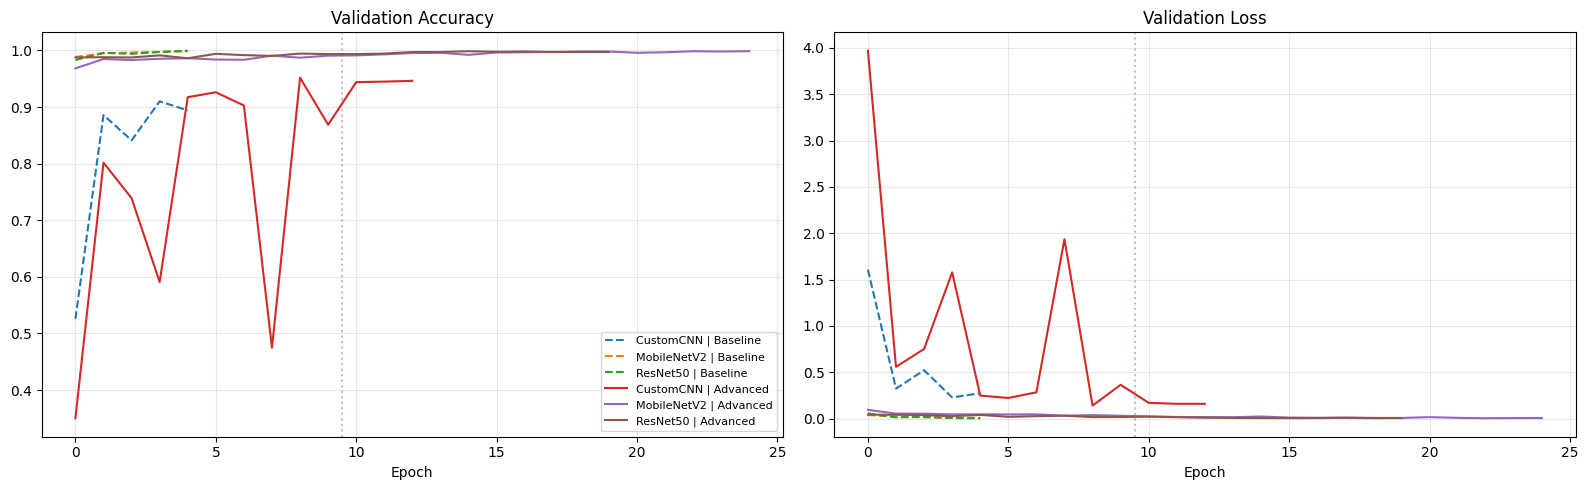

,Train Acc,Val Acc,Gap (Train - Val)
CustomCNN | Baseline,0.9245,0.8940,0.0305
MobileNetV2 | Baseline,1.0000,0.9986,0.0014
ResNet50 | Baseline,1.0000,0.9995,0.0005
CustomCNN | Advanced,0.9333,0.9463,-0.0131
MobileNetV2 | Advanced,0.9958,0.9986,-0.0029
ResNet50 | Advanced,0.9990,0.9972,0.0017


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))    # trái: Val Accuracy | phải: Val Loss
colors = plt.cm.tab10.colors                         # mỗi mô hình một màu
for i, (name, r) in enumerate(results.items()):
    h = r['history']
    ls = '--' if 'Baseline' in name else '-'         # Baseline: nét đứt | Advanced: nét liền
    axes[0].plot(h['val_accuracy'], ls, color=colors[i], label=name)
    axes[1].plot(h['val_loss'], ls, color=colors[i], label=name)
    if r['ft_start']:   # đánh dấu thời điểm bắt đầu fine-tune
        for ax in axes: ax.axvline(r['ft_start'] - 0.5, color=colors[i], alpha=0.25, ls=':')
axes[0].set_title('Validation Accuracy'); axes[1].set_title('Validation Loss')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# Khoảng cách train - val ở epoch cuối (dấu hiệu overfit)
# Gap lớn (Train cao hơn Val nhiều) -> overfit; cả hai đều thấp -> underfit
gap = pd.DataFrame({n: {'Train Acc': r['history']['accuracy'][-1], 'Val Acc': r['history']['val_accuracy'][-1]}
                    for n, r in results.items()}).T
gap['Gap (Train - Val)'] = gap['Train Acc'] - gap['Val Acc']
display(gap.style.format('{:.4f}'))

## 8. SO SÁNH & CHỌN MÔ HÌNH

- **Mô hình tốt nhất được chọn theo tập Validation** (Val Acc, hòa thì xét Val Loss). Tập Test không tham gia vào việc chọn.
- Test Acc / Macro-F1 của mọi mô hình chỉ để **báo cáo**.

### Kỹ thuật: chọn mô hình theo Validation, không theo Test
**Vấn đề:** nếu chọn mô hình có Test Acc cao nhất rồi lại báo cáo chính Test Acc đó, kết quả sẽ **lạc quan hơn thực tế**. Mô hình chiến thắng một phần nhờ may mắn trên tập Test cụ thể này, tức là Test đã bị "dùng" để ra quyết định (rò rỉ quyết định).

**Cách làm:** mọi quyết định (chọn mô hình, dừng sớm, giảm lr) chỉ dựa trên Validation. Test được giữ như một "bài thi cuối kỳ", chỉ chấm một lần để báo cáo. Nhờ vậy Test Acc là ước lượng trung thực của hiệu năng khi gặp dữ liệu mới.

**Hòa Val Acc:** xét tiếp Val Loss thấp hơn, vì loss phản ánh cả mức độ "tự tin đúng" của mô hình chứ không chỉ đúng / sai.

### Các thước đo trong bảng so sánh

| Thước đo | Ý nghĩa | Vì sao dùng |
|---|---|---|
| **Params** | Số tham số của mô hình | Cho biết độ nặng / nhẹ; cần cân nhắc giữa độ chính xác và chi phí triển khai |
| **Val Acc / Val Loss** | Độ chính xác và mất mát trên Validation | Căn cứ để **chọn** mô hình |
| **Test Acc** | Tỉ lệ ảnh Test dự đoán đúng | Báo cáo hiệu năng trên dữ liệu chưa thấy |
| **Test Macro-F1** | Trung bình cộng F1 của từng lớp, **mỗi lớp có trọng số ngang nhau** | Accuracy có thể cao nhờ lớp đông; Macro-F1 chỉ cao khi **mọi lớp** đều tốt, nên phản ánh tốt hơn khi dữ liệu mất cân bằng |

Hàm `predict_all` duyệt Test đúng một lượt và thu cả nhãn thật lẫn dự đoán, nên hai mảng luôn **khớp thứ tự** (không bị lệch nếu dataset có xáo trộn).

In [ ]:
def predict_all(model, ds):
    """Một lượt duyệt duy nhất -> nhãn thật và dự đoán luôn khớp thứ tự."""
    y_true, y_prob = [], []
    for x, y in ds:
        y_prob.append(model(x, training=False).numpy())   # training=False: tắt augmentation và dropout
        y_true.append(y.numpy())
    return np.concatenate(y_true), np.concatenate(y_prob)

# Đánh giá cả 6 mô hình trên Test để lập bảng so sánh (chỉ báo cáo, KHÔNG dùng để chọn mô hình)
rows = []
for name, r in results.items():
    y_true, y_prob = predict_all(r['model'], test_ds)
    y_pred = y_prob.argmax(axis=1)                        # lớp có xác suất cao nhất
    r['y_true'], r['y_pred'] = y_true, y_pred             # lưu lại để dùng ở mục 9
    rows.append({'Mô hình': name, 'Params': r['params'],
                 'Val Acc': r['val_acc'], 'Val Loss': r['val_loss'],
                 'Test Acc': (y_pred == y_true).mean(),
                 'Test Macro-F1': f1_score(y_true, y_pred, average='macro')})   # Macro-F1: trung bình F1 của các lớp, coi các lớp ngang nhau

comparison = pd.DataFrame(rows).set_index('Mô hình')
display(comparison.style.format({'Params': '{:,}', 'Val Acc': '{:.4f}', 'Val Loss': '{:.4f}',
                                 'Test Acc': '{:.4f}', 'Test Macro-F1': '{:.4f}'}))

# Chọn mô hình tốt nhất CHỈ dựa vào Validation: Val Acc cao nhất, nếu hòa thì Val Loss thấp nhất
best_name = comparison.sort_values(['Val Acc', 'Val Loss'], ascending=[False, True]).index[0]
best = results[best_name]
print(f'\n>>> Mô hình tốt nhất theo VALIDATION: {best_name}')

,Params,Val Acc,Val Loss,Test Acc,Test Macro-F1
Mô hình,,,,,
CustomCNN | Baseline,"1,199,462",0.8940,0.2741,0.8929,0.8983
MobileNetV2 | Baseline,"2,422,726",0.9986,0.0073,0.9967,0.9968
ResNet50 | Baseline,"23,850,758",0.9995,0.0030,0.9974,0.9973
CustomCNN | Advanced,"1,199,462",0.9518,0.1405,0.9600,0.9605
MobileNetV2 | Advanced,"2,422,726",0.9986,0.0042,0.9967,0.9965
ResNet50 | Advanced,"23,850,758",0.9977,0.0052,0.9963,0.9963



>>> Mô hình tốt nhất theo VALIDATION: ResNet50 | Baseline


## 9. ĐÁNH GIÁ CHUYÊN SÂU TRÊN TẬP TEST ĐỘC LẬP

Accuracy tổng chỉ cho biết "đúng bao nhiêu phần trăm", không cho biết **sai ở đâu**. Mục này phân tích sâu mô hình đã chọn.

### Kỹ thuật: Classification report (Precision / Recall / F1 theo từng lớp)

| Chỉ số | Công thức | Trả lời câu hỏi |
|---|---|---|
| **Precision** | TP / (TP + FP) | Trong số ảnh mô hình **gán** vào lớp này, bao nhiêu thật sự thuộc lớp này? |
| **Recall** | TP / (TP + FN) | Trong số ảnh **thật sự** thuộc lớp này, mô hình tìm ra được bao nhiêu? |
| **F1-score** | 2·P·R / (P + R) | Trung bình điều hòa của hai chỉ số trên; thấp nếu một trong hai thấp |

**Ý nghĩa với bài toán quả hỏng:** hai loại sai có hậu quả khác nhau. Bỏ sót quả hỏng (Recall của lớp `rotten*` thấp) khiến quả hỏng lọt vào lô hàng tốt; nhận nhầm quả tươi thành hỏng (Precision của lớp `rotten*` thấp) gây lãng phí. Báo cáo theo từng lớp giúp thấy rõ mô hình yếu ở loại sai nào.

### Kỹ thuật: Ma trận nhầm lẫn (confusion matrix)
**Là gì:** bảng mà hàng là lớp thật, cột là lớp dự đoán; ô (i, j) là số ảnh lớp i bị dự đoán thành lớp j. Đường chéo là dự đoán đúng.

**Hai phiên bản:**
- **Số lượng:** cho thấy quy mô thực tế của từng loại nhầm lẫn.
- **Chuẩn hóa theo hàng (= Recall):** mỗi hàng cộng lại bằng 1, nên so sánh được giữa lớp nhiều ảnh và lớp ít ảnh.

**Giúp gì:** chỉ ra mô hình hay nhầm lớp nào với lớp nào. Với dataset này, cần chú ý các nhầm lẫn giữa quả tươi và quả hỏng **của cùng một loại quả**, vì đó là phần khó nhất của bài toán.

### Kỹ thuật: Top cặp lớp bị nhầm nhiều nhất
Xóa đường chéo của ma trận rồi liệt kê 5 ô lớn nhất. Đây là danh sách điểm yếu cụ thể để phân tích lỗi (error analysis) và đề xuất hướng cải thiện (thêm dữ liệu cho cặp lớp đó, đổi augmentation, v.v.).

Test Accuracy (ResNet50 | Baseline): 99.74%

CLASSIFICATION REPORT (Precision / Recall / F1 theo từng lớp):
               precision    recall  f1-score   support

  freshapples     0.9925    1.0000    0.9962       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     0.9949    0.9974    0.9961       388
 rottenapples     0.9967    0.9967    0.9967       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     1.0000    0.9901    0.9950       403

     accuracy                         0.9974      2698
    macro avg     0.9973    0.9974    0.9973      2698
 weighted avg     0.9974    0.9974    0.9974      2698



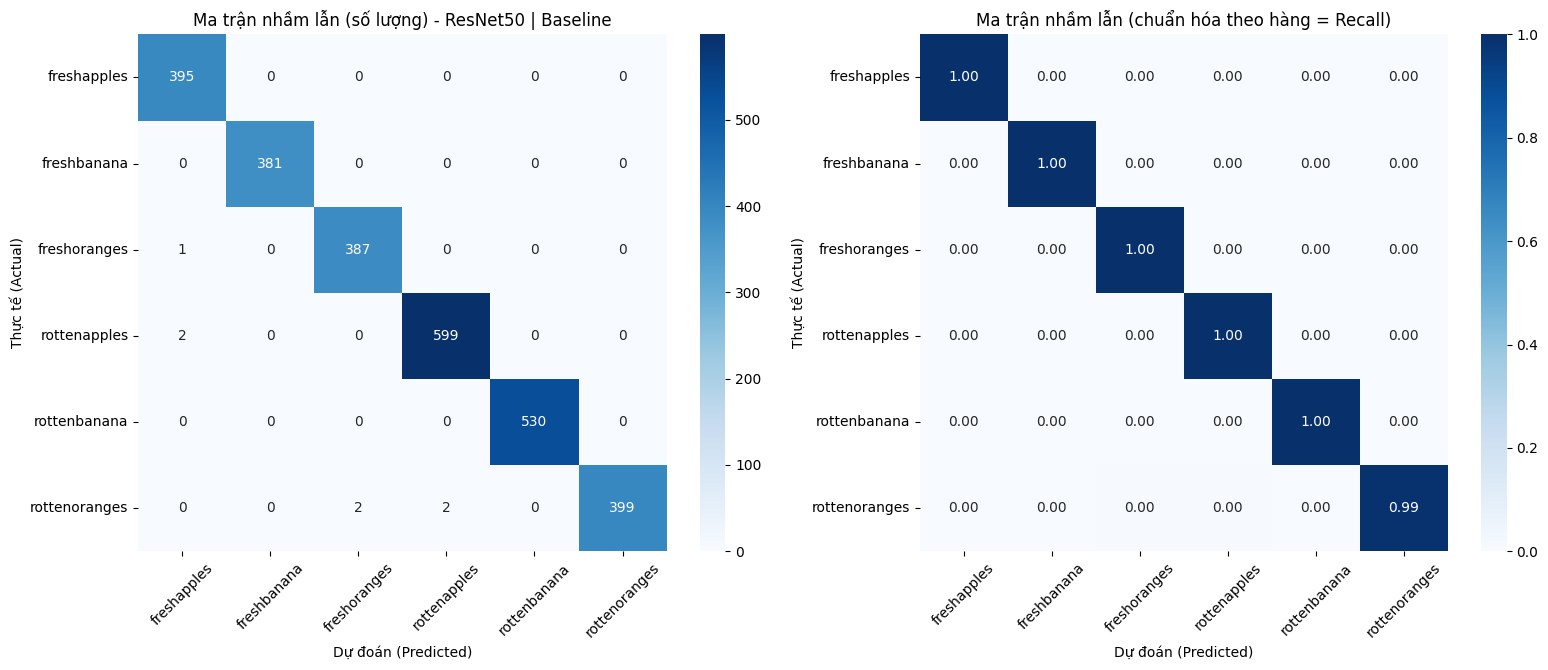

Top cặp bị nhầm (Thực tế -> Dự đoán):
              rottenoranges -> rottenapples              : 2 ảnh
              rottenoranges -> freshoranges              : 2 ảnh
               rottenapples -> freshapples               : 2 ảnh
               freshoranges -> freshapples               : 1 ảnh


In [ ]:
y_true, y_pred = best['y_true'], best['y_pred']      # nhãn thật & dự đoán của mô hình được chọn
print(f'Test Accuracy ({best_name}): {(y_true == y_pred).mean() * 100:.2f}%\n')
print('CLASSIFICATION REPORT (Precision / Recall / F1 theo từng lớp):')
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Ma trận nhầm lẫn: hàng = lớp thật, cột = lớp dự đoán
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)   # chuẩn hóa theo hàng (= Recall); clip tránh chia cho 0

size = max(8, NUM_CLASSES * 0.9)                           # kích thước hình tự co giãn theo số lớp
fig, axes = plt.subplots(1, 2, figsize=(2 * size, size * 0.85))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f'Ma trận nhầm lẫn (số lượng) - {best_name}')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Ma trận nhầm lẫn (chuẩn hóa theo hàng = Recall)')
for ax in axes:
    ax.set_xlabel('Dự đoán (Predicted)'); ax.set_ylabel('Thực tế (Actual)')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# Các cặp lớp bị nhầm nhiều nhất
off = cm.copy(); np.fill_diagonal(off, 0)                  # xóa đường chéo (dự đoán đúng), chỉ giữ các ô nhầm lẫn
pairs = sorted(((off[i, j], class_names[i], class_names[j])
                for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0), reverse=True)[:5]   # lấy top 5
print('Top cặp bị nhầm (Thực tế -> Dự đoán):')
for n, a, b in pairs: print(f'  {a:>25} -> {b:<25} : {n} ảnh')
if not pairs: print('  (Không có ảnh nào bị nhầm)')

## 10. LƯU KẾT QUẢ

| Tệp | Nội dung | Dùng để làm gì |
|---|---|---|
| `best_model.weights.h5` | Trọng số của mô hình tốt nhất (đã chọn theo Validation) | Nạp lại mô hình mà không cần train lại: dựng đúng kiến trúc rồi `load_weights` |
| `class_names.json` | Danh sách tên lớp theo đúng thứ tự chỉ số nhãn | Khi dự đoán, ánh xạ chỉ số đầu ra (0 đến 5) về tên lớp |
| `model_comparison.csv` | Bảng so sánh 6 mô hình | Lấy số liệu điền vào báo cáo; lưu `utf-8-sig` để Excel mở tiếng Việt không lỗi font |

**Lưu ý khi triển khai:** mô hình đã gồm sẵn bước tiền xử lý, nên khi dự đoán chỉ cần đưa ảnh RGB 224 × 224 thang `[0, 255]`, không cần tự chuẩn hóa thêm.

In [ ]:
# Lưu trọng số mô hình tốt nhất (muốn dùng lại: dựng đúng kiến trúc rồi load_weights)
best['model'].save_weights(os.path.join(OUTPUT_DIR, 'best_model.weights.h5'))
# Lưu danh sách tên lớp để khi dự đoán biết chỉ số nhãn tương ứng với lớp nào
with open(os.path.join(OUTPUT_DIR, 'class_names.json'), 'w', encoding='utf-8') as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)
# Lưu bảng so sánh 6 mô hình (utf-8-sig để Excel mở không lỗi font tiếng Việt)
comparison.to_csv(os.path.join(OUTPUT_DIR, 'model_comparison.csv'), encoding='utf-8-sig')
print(f'Đã lưu trọng số mô hình "{best_name}", class_names.json và model_comparison.csv vào thư mục "{OUTPUT_DIR}/"')
print('Lưu ý: mô hình đã gồm sẵn bước tiền xử lý; khi dự đoán chỉ cần đưa ảnh RGB 224x224 thang [0, 255].')

Đã lưu trọng số mô hình "ResNet50 | Baseline", class_names.json và model_comparison.csv vào thư mục "outputs/"
Lưu ý: mô hình đã gồm sẵn bước tiền xử lý; khi dự đoán chỉ cần đưa ảnh RGB 224x224 thang [0, 255].


In [ ]:
# ==========================================
# MỤC 10: LƯU MÔ HÌNH VÀ TẢI VỀ MÁY
# ==========================================
import os, json
from google.colab import files

# 1. Lưu trọng số và TOÀN BỘ mô hình (định dạng chuẩn .keras)
best['model'].save_weights(os.path.join(OUTPUT_DIR, 'best_model.weights.h5'))
best['model'].save(os.path.join(OUTPUT_DIR, 'best_model.keras'))

# 2. Lưu danh sách nhãn và bảng so sánh
with open(os.path.join(OUTPUT_DIR, 'class_names.json'), 'w', encoding='utf-8') as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)
comparison.to_csv(os.path.join(OUTPUT_DIR, 'model_comparison.csv'), encoding='utf-8-sig')

# 3. Nén toàn bộ thư mục outputs thành file zip
!zip -q -r outputs_fruit_model.zip outputs/

# 4. Lưu trực tiếp bản sao vào Google Drive (nếu đã mount)
!mkdir -p /content/drive/MyDrive/Colab_Datasets
!cp outputs_fruit_model.zip /content/drive/MyDrive/Colab_Datasets/

print("Đã lưu kết quả vào thư mục outputs/ và sao lưu vào Google Drive!")

# 5. Tự động bật cửa sổ tải file về máy tính cá nhân
files.download('outputs_fruit_model.zip')

Đã lưu kết quả vào thư mục outputs/ và sao lưu vào Google Drive!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>